# Stemming and Lemitization


## Stemming

In [ ]:
from nltk.stem import PorterStemmer #stemming import command
stemmer = PorterStemmer()
words = ["running", "studying", "smiling", "communication"]
stemmed_words = [stemmer.stem(word) for word in words]
print(stemmed_words)

['run', 'studi', 'smile', 'commun']


## Lemitization


In [ ]:
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
nltk.download('wordnet')
lemmatizer = WordNetLemmatizer()
words = ["running", "better", "studies", "was"]
lemmas = [
    lemmatizer.lemmatize("running", pos=wordnet.VERB),
    lemmatizer.lemmatize("better", pos=wordnet.ADJ),
    lemmatizer.lemmatize("studies", pos=wordnet.NOUN),
    lemmatizer.lemmatize("was", pos=wordnet.VERB)
]
print(lemmas)

[nltk_data] Downloading package wordnet to /root/nltk_data...


['run', 'good', 'study', 'be']


# Data load

In [ ]:
import pandas as pd

In [ ]:
data = pd.read_csv("/content/twitter_training (1).csv", header=None)
data

,0,1,2,3
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
...,...,...,...,...
74677,9200,Nvidia,Positive,Just realized that the Windows partition of my...
74678,9200,Nvidia,Positive,Just realized that my Mac window partition is ...
74679,9200,Nvidia,Positive,Just realized the windows partition of my Mac ...
74680,9200,Nvidia,Positive,Just realized between the windows partition of...


In [ ]:
data.drop([0,1],axis=1,inplace=True)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   2       74682 non-null  object
 1   3       73996 non-null  object
dtypes: object(2)
memory usage: 1.1+ MB


In [ ]:
data.isna().sum()

,0
2,0
3,686


In [ ]:
data.dropna(inplace=True)

In [ ]:
data.isna().sum()

,0
2,0
3,0


In [ ]:
data.rename(columns={2:"Sentiment",3:"Review"},inplace=True)

In [ ]:
data

,Sentiment,Review
0,Positive,im getting on borderlands and i will murder yo...
1,Positive,I am coming to the borders and I will kill you...
2,Positive,im getting on borderlands and i will kill you ...
3,Positive,im coming on borderlands and i will murder you...
4,Positive,im getting on borderlands 2 and i will murder ...
...,...,...
74677,Positive,Just realized that the Windows partition of my...
74678,Positive,Just realized that my Mac window partition is ...
74679,Positive,Just realized the windows partition of my Mac ...
74680,Positive,Just realized between the windows partition of...


In [ ]:
data.duplicated().sum()

np.int64(4227)

In [ ]:
data.drop_duplicates(inplace=True)

In [ ]:
data.duplicated().sum()

np.int64(0)

<Axes: xlabel='Sentiment'>

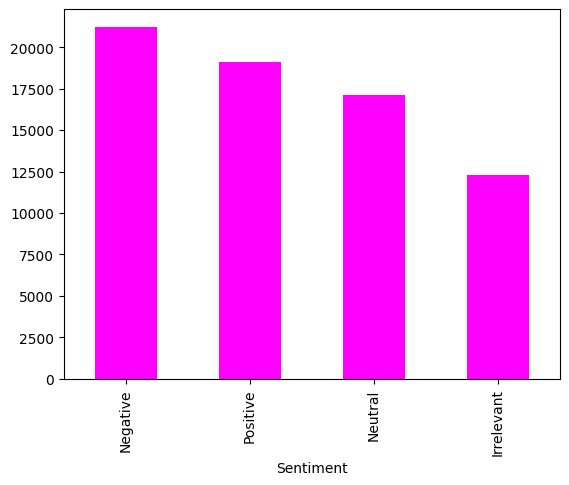

In [ ]:
data.Sentiment.value_counts().plot(kind="bar", color = 'magenta')

In [ ]:
data

,Sentiment,Review
0,Positive,im getting on borderlands and i will murder yo...
1,Positive,I am coming to the borders and I will kill you...
2,Positive,im getting on borderlands and i will kill you ...
3,Positive,im coming on borderlands and i will murder you...
4,Positive,im getting on borderlands 2 and i will murder ...
...,...,...
74677,Positive,Just realized that the Windows partition of my...
74678,Positive,Just realized that my Mac window partition is ...
74679,Positive,Just realized the windows partition of my Mac ...
74680,Positive,Just realized between the windows partition of...


In [ ]:
import string
import nltk
import re
from nltk.corpus import stopwords
nltk.download('stopwords')
def Text_Preprocessor(text):
  text = text.lower()
  text = re.sub("\d","",text)
  text = re.sub("\s+"," ",text)
  text = text.encode("ascii","ignore").decode("ascii")
  text = text.replace(string.punctuation,'')
  text = " ".join([a for a in text.split() if a not in stopwords.words('english')])
  return text

<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:9: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:9: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_924/3877630433.py:8: SyntaxWarning: invalid escape sequence '\d'
  text = re.sub("\d","",text)
/tmp/ipykernel_924/3877630433.py:9: SyntaxWarning: invalid escape sequence '\s'
  text = re.sub("\s+"," ",text)
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
data['Review'] = data['Review'].apply(Text_Preprocessor)

In [ ]:
print(data.Review[0])

im getting borderlands murder ,


## Tokenization

In [ ]:
!pip install tensorflow
from tensorflow.keras.preprocessing.text import Tokenizer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 18.6 MB/s  0:00:16
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 84.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [tensorflow]


/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


In [ ]:
tok = Tokenizer()

In [ ]:
tok.fit_on_texts(data["Review"])

In [ ]:
data["Review"] = tok.texts_to_sequences(data["Review"])

In [ ]:
tok.word_index

{'com': 1,
 'game': 2,
 'like': 3,
 'get': 4,
 'pic': 5,
 'twitter': 6,
 'one': 7,
 'good': 8,
 'play': 9,
 'new': 10,
 'really': 11,
 'love': 12,
 'unk': 13,
 'johnson': 14,
 'it': 15,
 'see': 16,
 'people': 17,
 'shit': 18,
 'time': 19,
 'co': 20,
 'best': 21,
 't': 22,
 'still': 23,
 'facebook': 24,
 'https': 25,
 'games': 26,
 'got': 27,
 'go': 28,
 'amazon': 29,
 'great': 30,
 'even': 31,
 'playing': 32,
 'xbox': 33,
 'google': 34,
 'fucking': 35,
 'rhandlerr': 36,
 'please': 37,
 'microsoft': 38,
 'dead': 39,
 'fuck': 40,
 'us': 41,
 'verizon': 42,
 'back': 43,
 'ps': 44,
 'much': 45,
 'im': 46,
 'red': 47,
 'fifa': 48,
 'going': 49,
 'would': 50,
 'know': 51,
 'tv': 52,
 'home': 53,
 "can't": 54,
 'make': 55,
 'pubg': 56,
 'player': 57,
 'day': 58,
 'first': 59,
 'fun': 60,
 'today': 61,
 'also': 62,
 'nvidia': 63,
 'gta': 64,
 'borderlands': 65,
 'want': 66,
 'fix': 67,
 'ever': 68,
 'bad': 69,
 'twitch': 70,
 'x': 71,
 'thank': 72,
 'v': 73,
 'never': 74,
 'ban': 75,
 'call': 

In [ ]:
data.Sentiment.value_counts()

,count
Sentiment,
Negative,21237
Positive,19138
Neutral,17110
Irrelevant,12284


In [ ]:
sentiment_map = {
    'Negative': 0,
    'Positive': 1,
    'Neutral': 2,
    'Irrelevant': 4
}

data['Sentiment'] = data['Sentiment'].map(sentiment_map)
data

,Sentiment,Review
0,1,"[46, 92, 65, 1637]"
1,1,"[286, 6394, 320, 357]"
2,1,"[46, 92, 65, 320, 357]"
3,1,"[46, 286, 65, 1637, 357]"
4,1,"[46, 92, 65, 1637, 357]"
...,...,...
74677,1,"[1821, 481, 13086, 1858, 3, 123, 657, 63, 1203..."
74678,1,"[1821, 1858, 4147, 13086, 123, 657, 63, 1203, ..."
74679,1,"[1821, 481, 13086, 1858, 123, 657, 63, 1203, 4..."
74680,1,"[1821, 481, 13086, 1858, 3, 123, 657, 63, 1203..."


## Padding

In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [ ]:
len(tok.word_index)

30482

In [ ]:
# Calculate the length of each review sequence
review_lengths = [len(a) for a in data["Review"]]

# Or to see the maximum sequence length
max_len = max(review_lengths)
print("Maximum sequence length:", max_len)

Maximum sequence length: 163


In [ ]:
X = pad_sequences(data["Review"],maxlen=163,padding="post")

In [ ]:
data

,Sentiment,Review
0,1,"[46, 92, 65, 1637]"
1,1,"[286, 6394, 320, 357]"
2,1,"[46, 92, 65, 320, 357]"
3,1,"[46, 286, 65, 1637, 357]"
4,1,"[46, 92, 65, 1637, 357]"
...,...,...
74677,1,"[1821, 481, 13086, 1858, 3, 123, 657, 63, 1203..."
74678,1,"[1821, 1858, 4147, 13086, 123, 657, 63, 1203, ..."
74679,1,"[1821, 481, 13086, 1858, 123, 657, 63, 1203, 4..."
74680,1,"[1821, 481, 13086, 1858, 3, 123, 657, 63, 1203..."


In [ ]:
X

array([[   46,    92,    65, ...,     0,     0,     0],
       [  286,  6394,   320, ...,     0,     0,     0],
       [   46,    92,    65, ...,     0,     0,     0],
       ...,
       [ 1821,   481, 13086, ...,     0,     0,     0],
       [ 1821,   481, 13086, ...,     0,     0,     0],
       [    3,   481, 13086, ...,     0,     0,     0]],
      shape=(69769, 163), dtype=int32)

In [ ]:
y = data.Sentiment

## Train/Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (55815, 163)
X_test shape: (13954, 163)


In [ ]:
from tensorflow import keras

In [ ]:
from tensorflow.keras import layers

### With RNN


In [ ]:
vocab_size = len(tok.word_index) + 1  # 30483
embedding_dim = 32

# Redefine the model with return_sequences=True and 5 output units
model = keras.Sequential([
    layers.Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=163),
    layers.SimpleRNN(128, activation='relu', return_sequences=True),
    layers.SimpleRNN(256, activation='relu'),
    layers.Dense(5, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=10, validation_split=0.2)

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


1396/1396 ━━━━━━━━━━━━━━━━━━━━ 100s 70ms/step - accuracy: 0.2935 - loss: 1.3742 - val_accuracy: 0.3062 - val_loss: 1.3720
Epoch 2/10
1396/1396 ━━━━━━━━━━━━━━━━━━━━ 97s 70ms/step - accuracy: 0.3005 - loss: 1.3694 - val_accuracy: 0.3062 - val_loss: 1.3721
Epoch 3/10
1396/1396 ━━━━━━━━━━━━━━━━━━━━ 98s 70ms/step - accuracy: 0.3016 - loss: 1.3684 - val_accuracy: 0.3062 - val_loss: 1.3673
Epoch 4/10
1396/1396 ━━━━━━━━━━━━━━━━━━━━ 99s 71ms/step - accuracy: 0.3025 - loss: 1.3678 - val_accuracy: 0.3062 - val_loss: 1.3666
Epoch 5/10
1396/1396 ━━━━━━━━━━━━━━━━━━━━ 98s 70ms/step - accuracy: 0.3036 - loss: 1.3675 - val_accuracy: 0.2751 - val_loss: 1.3678
Epoch 6/10
1396/1396 ━━━━━━━━━━━━━━━━━━━━ 97s 69ms/step - accuracy: 0.3025 - loss: 154166416.0000 - val_accuracy: 0.3062 - val_loss: 1.3686
Epoch 7/10
1396/1396 ━━━━━━━━━━━━━━━━━━━━ 98s 70ms/step - accuracy: 0.3036 - loss: 1.3673 - val_accuracy: 0.3062 - val_loss: 1.3663
Epoch 8/10
1396/1396 ━━━━━━━━━━━━━━━━━━━━ 97s 69ms/step - accuracy: 0.3035 - l

### With LSTM


In [ ]:
vocab_size = len(tok.word_index) + 1  # 30483
embedding_dim = 32

# Redefine the model with return_sequences=True and 5 output units
model = keras.Sequential([
    layers.Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=163),
    layers.LSTM(128, activation='relu', return_sequences=True),
    layers.LSTM(256, activation='relu'),
    layers.Dense(5, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=5, validation_split=0.2)

Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


1396/1396 ━━━━━━━━━━━━━━━━━━━━ 496s 354ms/step - accuracy: 0.3029 - loss: 157604659200.0000 - val_accuracy: 0.3062 - val_loss: 1.3739
Epoch 2/5
1396/1396 ━━━━━━━━━━━━━━━━━━━━ 490s 351ms/step - accuracy: 0.3036 - loss: 1.3684 - val_accuracy: 0.3062 - val_loss: 1.3665
Epoch 3/5
1396/1396 ━━━━━━━━━━━━━━━━━━━━ 493s 353ms/step - accuracy: 0.3033 - loss: nan - val_accuracy: 0.3062 - val_loss: nan
Epoch 4/5
1396/1396 ━━━━━━━━━━━━━━━━━━━━ 490s 351ms/step - accuracy: 0.3036 - loss: nan - val_accuracy: 0.3062 - val_loss: nan
Epoch 5/5
1396/1396 ━━━━━━━━━━━━━━━━━━━━ 489s 350ms/step - accuracy: 0.3036 - loss: nan - val_accuracy: 0.3062 - val_loss: nan


### With GRU

In [ ]:
vocab_size = len(tok.word_index) + 1  # 30483
embedding_dim = 32

# Redefine the model with return_sequences=True and 5 output units
model = keras.Sequential([
    layers.Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=163),
    layers.GRU(128, activation='relu', return_sequences=True),
    layers.GRU(256, activation='relu'),
    layers.Dense(5, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=10, validation_split=0.2)